# Duckiematrix DQN: training and learning-progress dashboard

Analyze the **20,000-step** CNN-DQN lane-following experiment. This notebook reads `training/logs/episode_rewards.csv` as written by the current training pipeline. It uses measured episode length and reward, estimates the exploration schedule, and optionally reads **independent greedy-policy evaluations** from a separate CSV.

**Important:** Training curves describe the *epsilon-greedy behavior policy*. They cannot, by themselves, prove that the greedy CNN policy improves. A deterministic evaluation requires running the saved policy with `model.predict(obs, deterministic=True)` on repeatable starts and separately recording its outcomes. No evaluation data is invented here.

**What this notebook gives you:** data validation; training-step x-axis; reward/step, episode survival and total return; rolling trends; exploration schedule; a labeled heuristic score; length-versus-reward diagnostics; optional greedy evaluation curves; and a final numerical summary.

In [ ]:
from pathlib import Path
import csv
import math
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

plt.rcParams.update({"figure.figsize": (11, 5), "axes.grid": True, "grid.alpha": 0.25})

# Paths work when launched from the project root, training/, or a notebook subfolder.
def find_training_dir():
    for base in (Path.cwd(), *Path.cwd().parents):
        candidate = base / "training"
        if candidate.is_dir():
            return candidate
        if base.name == "training" and base.is_dir():
            return base
    return Path.cwd() / "training"

TRAINING_DIR = find_training_dir()
EPISODE_CSV = TRAINING_DIR / "logs" / "episode_rewards.csv"
EVAL_CSV = TRAINING_DIR / "logs" / "evaluation_rewards.csv"  # optional

TOTAL_TIMESTEPS = 50_000
EXPLORATION_INITIAL_EPS = 1.0
EXPLORATION_FINAL_EPS = 0.05
EXPLORATION_FRACTION = 0.50
LEARNING_STARTS = 1000
SMOOTH_WINDOW = 10

# Heuristic visualization only: not an independent evaluation of the policy.
TARGET_STEPS = 500
GOOD_REWARD_PER_STEP = 0.5

print("Training CSV:", EPISODE_CSV)
print("Optional evaluation CSV:", EVAL_CSV)


Training CSV: /home/svandenberk/Downloads/Duckiebot_Lab_Starter_Kit/MOL_DFL_VaSe_VaSe/training/logs/episode_rewards.csv
Optional evaluation CSV: /home/svandenberk/Downloads/Duckiebot_Lab_Starter_Kit/MOL_DFL_VaSe_VaSe/training/logs/evaluation_rewards.csv


## 1. Load and validate completed training episodes

Only valid, completed CSV rows are included. A partially written row is ignored. We expect the existing columns `episode`, `steps`, and `reward_total`; optional additional fields are retained. The notebook never treats episode number as the number of training steps. The cumulative-step estimate is exact only if the CSV contains **all episodes since the beginning of training**; it excludes any incomplete final episode and does not account for discarded logs or resumed training.

In [2]:
def read_episode_csv(path):
    required = {"episode", "steps", "reward_total"}
    if not path.is_file():
        print(f"No episode log at {path}. Run training first.")
        return pd.DataFrame(columns=["episode", "steps", "reward_total"])

    with path.open(newline="", encoding="utf-8") as f:
        reader = csv.DictReader(f)
        if not required.issubset(reader.fieldnames or []):
            raise ValueError(f"Expected CSV columns {sorted(required)}; got {reader.fieldnames}")
        records = []
        skipped = 0
        for row in reader:
            try:
                ep = int(row["episode"])
                steps = int(row["steps"])
                reward = float(row["reward_total"])
                if steps <= 0 or not math.isfinite(reward):
                    raise ValueError("Invalid episode row")
                records.append({"episode": ep, "steps": steps, "reward_total": reward})
            except (ValueError, TypeError, KeyError):
                skipped += 1
    if skipped:
        warnings.warn(f"Skipped {skipped} incomplete/invalid rows")
    df = pd.DataFrame(records, columns=["episode", "steps", "reward_total"])
    if df.empty:
        return df
    if df["episode"].duplicated().any() or df["episode"].diff().dropna().lt(0).any():
        warnings.warn("Episode IDs repeat or are out of order; check whether multiple runs were appended.")
    df["training_steps_est"] = df["steps"].cumsum()
    df["reward_per_step"] = df["reward_total"] / df["steps"]
    return df

train = read_episode_csv(EPISODE_CSV)
print(f"Loaded {len(train)} complete episodes")
if not train.empty:
    display(train.tail(8))


Loaded 63 complete episodes


,episode,steps,reward_total,training_steps_est,reward_per_step
55,56,98,581.176235,6317,5.930370
56,57,98,652.468758,6415,6.657844
57,58,141,1317.997950,6556,9.347503
58,59,94,366.345493,6650,3.897292
59,60,79,453.706377,6729,5.743119
60,61,97,516.771273,6826,5.327539
61,62,80,585.152159,6906,7.314402
62,63,96,910.937733,7002,9.488935


## 2. Exploration schedule and a transparent heuristic score

The *approximate* epsilon schedule below follows the configured Stable-Baselines3 linear decay. `learning_starts` controls the beginning of gradient updates; it does not override the epsilon schedule. During training, greedy actions from an untrained network are not evidence of learned skill.

The optional `run_score` is a dashboard convenience, **not** a scientifically validated metric. It needs both survival and positive mean reward. It saturates, so it should *never* replace right-lane distance or laps in an evaluation.

In [3]:
def epsilon_at(t):
    decay_steps = TOTAL_TIMESTEPS * EXPLORATION_FRACTION
    fraction = np.clip(np.asarray(t, dtype=float) / decay_steps, 0.0, 1.0)
    return EXPLORATION_INITIAL_EPS + fraction * (EXPLORATION_FINAL_EPS - EXPLORATION_INITIAL_EPS)


def run_score(reward_total, steps):
    """0–100 descriptive score; rewards and episode length must be comparable."""
    if steps <= 0:
        return 0.0
    survival = min(steps / TARGET_STEPS, 1.0)
    quality = np.clip((reward_total / steps) / GOOD_REWARD_PER_STEP, 0.0, 1.0)
    return float(100 * survival * quality)

if not train.empty:
    train["epsilon_approx"] = epsilon_at(train["training_steps_est"].to_numpy())
    train["run_score"] = [run_score(r, s) for r, s in zip(train.reward_total, train.steps)]
    display(train[["episode", "training_steps_est", "epsilon_approx", "steps", "reward_per_step", "run_score"]].tail(8))


,episode,training_steps_est,epsilon_approx,steps,reward_per_step,run_score
55,56,6317,0.499904,98,5.930370,19.6
56,57,6415,0.492146,98,6.657844,19.6
57,58,6556,0.480983,141,9.347503,28.2
58,59,6650,0.473542,94,3.897292,18.8
59,60,6729,0.467288,79,5.743119,15.8
60,61,6826,0.459608,97,5.327539,19.4
61,62,6906,0.453275,80,7.314402,16.0
62,63,7002,0.445675,96,9.488935,19.2


## 3. Training curves (against cumulative environment steps)

A 10-episode moving average helps reveal trends, but varies in training-step coverage as episode lengths change. Mean reward/step in this window is computed as **sum of rewards divided by sum of steps**, rather than as an unweighted average of per-episode rates.

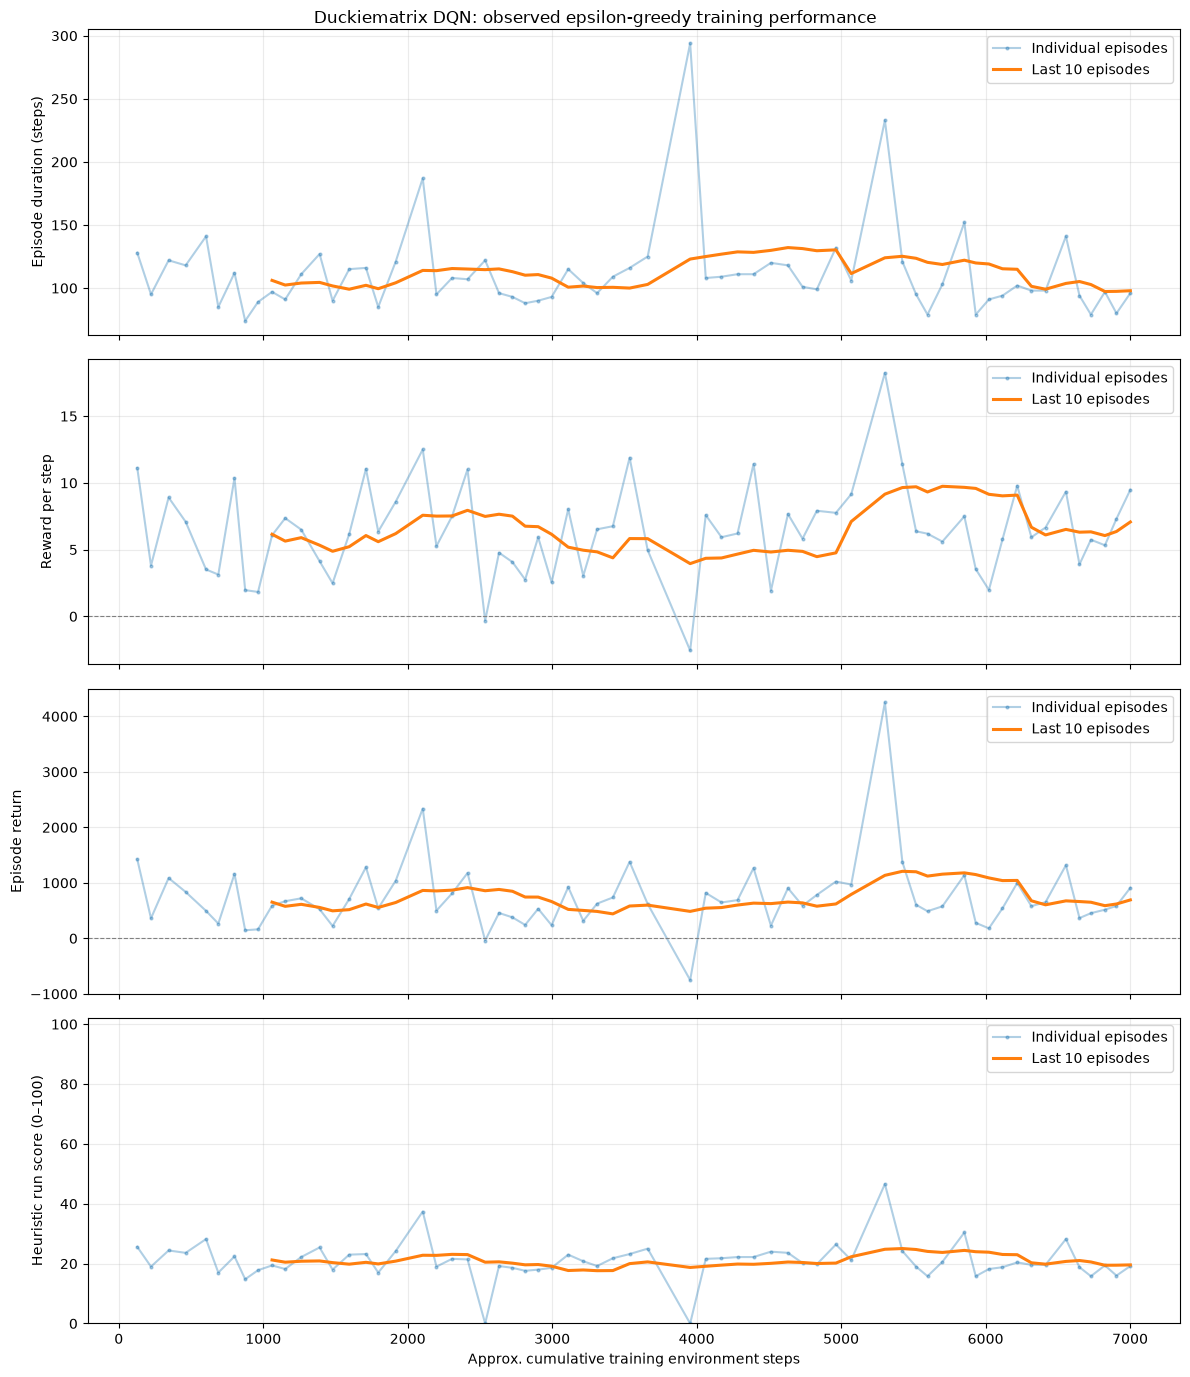

In [4]:
if train.empty:
    print("Training curves unavailable until at least one complete episode is logged.")
else:
    x = train["training_steps_est"]
    w = min(SMOOTH_WINDOW, len(train))
    fig, axes = plt.subplots(4, 1, figsize=(12, 14), sharex=True)
    specs = [
        ("steps", "Episode duration (steps)"),
        ("reward_per_step", "Reward per step"),
        ("reward_total", "Episode return"),
        ("run_score", "Heuristic run score (0–100)"),
    ]
    for ax, (col, label) in zip(axes, specs):
        ax.plot(x, train[col], marker=".", ms=4, alpha=0.35, label="Individual episodes")
        if col == "reward_per_step":
            smoothed = (train.reward_total.rolling(w, min_periods=w).sum() /
                        train.steps.rolling(w, min_periods=w).sum())
        else:
            smoothed = train[col].rolling(w, min_periods=w).mean()
        ax.plot(x, smoothed, linewidth=2.2, label=f"Last {w} episodes")
        ax.set_ylabel(label)
        ax.legend(loc="best")
        if col in ("reward_per_step", "reward_total"):
            ax.axhline(0, linewidth=0.8, linestyle="--", color="gray")
        if col == "run_score":
            ax.set_ylim(0, 102)
    axes[-1].set_xlabel("Approx. cumulative training environment steps")
    fig.suptitle("Duckiematrix DQN: observed epsilon-greedy training performance")
    plt.tight_layout()
    plt.show()


## 4. Exploration overlay

This makes it easier to see how much of a training improvement coincides with fewer randomly chosen actions. The curves remain observational: less exploration and a better network both affect training episode outcomes.

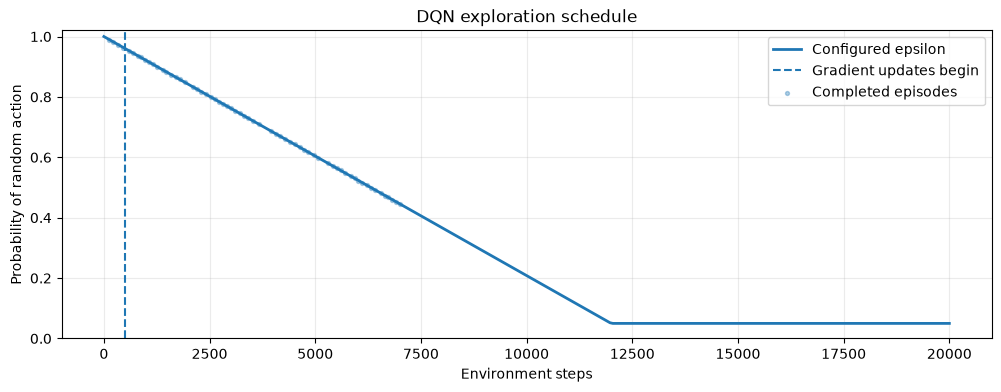

In [5]:
fig, ax = plt.subplots(figsize=(12, 4))
t = np.linspace(0, TOTAL_TIMESTEPS, 300)
ax.plot(t, epsilon_at(t), label="Configured epsilon", linewidth=2)
ax.axvline(LEARNING_STARTS, linestyle="--", label="Gradient updates begin")
if not train.empty:
    ax.scatter(train.training_steps_est, train.epsilon_approx, s=8, alpha=0.35,
               label="Completed episodes")
ax.set(xlabel="Environment steps", ylabel="Probability of random action", ylim=(0, 1.02),
       title="DQN exploration schedule")
ax.legend()
plt.show()


## 5. Diagnostics: does survival correlate with actual reward?

A long episode with low or negative reward can indicate stalled behavior, weak penalties, or a termination condition that does not reliably detect leaving the road. A short high-reward episode could simply be a brief correctly centered run followed by failure. Neither case tells you how many laps were completed.

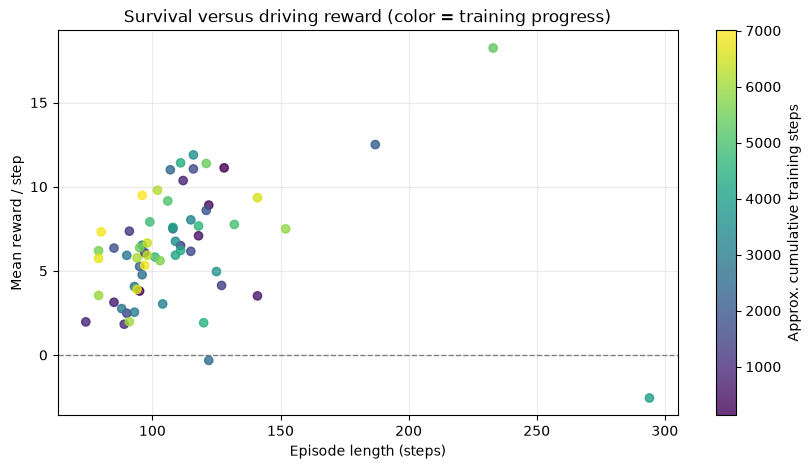

,first episodes,last episodes
Mean duration (steps),106.100,97.900
Weighted reward / step,6.153,7.074
Mean heuristic score,21.220,19.580


Descriptive comparison only: training exploration levels differ between these periods.


In [6]:
if train.empty:
    print("No completed episodes to diagnose.")
else:
    fig, ax = plt.subplots(figsize=(10, 5))
    scatter = ax.scatter(train.steps, train.reward_per_step,
                         c=train.training_steps_est, cmap="viridis", alpha=0.8)
    ax.axhline(0, color="gray", linestyle="--", linewidth=1)
    ax.set(xlabel="Episode length (steps)", ylabel="Mean reward / step",
           title="Survival versus driving reward (color = training progress)")
    plt.colorbar(scatter, ax=ax, label="Approx. cumulative training steps")
    plt.show()

    n = min(10, len(train))
    first, last = train.head(n), train.tail(n)
    summary = pd.DataFrame({
        "first episodes": {
            "Mean duration (steps)": first.steps.mean(),
            "Weighted reward / step": first.reward_total.sum() / first.steps.sum(),
            "Mean heuristic score": first.run_score.mean(),
        },
        "last episodes": {
            "Mean duration (steps)": last.steps.mean(),
            "Weighted reward / step": last.reward_total.sum() / last.steps.sum(),
            "Mean heuristic score": last.run_score.mean(),
        },
    })
    display(summary.round(3))
    print("Descriptive comparison only: training exploration levels differ between these periods.")


## 6. Independent greedy-policy evaluation (optional, strongly recommended)

A separate evaluator should periodically run saved checkpoints using **`deterministic=True`**, preferably from several fixed initial positions and with a fixed maximum evaluation horizon. This evaluation requires interacting with a **separate environment or an isolated stopped training environment**; the notebook does not claim to run such episodes.

Save evaluation results to `training/logs/evaluation_rewards.csv` with at least:

```csv
training_steps,episode,valid_distance_m,laps_completed
2000,1,1.2,0
2000,2,0.9,0
4000,1,2.0,0
```

These rows are **format examples only**. Add real measurements from your evaluation code. `valid_distance_m` should be measured in the right lane, not just straight-line displacement or unrestricted odometry. Lap counts are optional and should be measured with a checkpoint or track-position mechanism. Keep a stable evaluation protocol between checkpoints.

In [7]:
def load_evaluation_csv(path):
    required = {"training_steps", "valid_distance_m"}
    if not path.is_file():
        return pd.DataFrame()
    df = pd.read_csv(path)
    if not required.issubset(df.columns):
        warnings.warn(f"Evaluation CSV missing required columns {sorted(required)}")
        return pd.DataFrame()
    for col in ("training_steps", "valid_distance_m", "laps_completed"):
        if col in df:
            df[col] = pd.to_numeric(df[col], errors="coerce")
    df = df.replace([np.inf, -np.inf], np.nan).dropna(subset=list(required))
    df = df[(df.training_steps >= 0) & (df.valid_distance_m >= 0)]
    if "laps_completed" in df:
        df = df[df.laps_completed.isna() | (df.laps_completed >= 0)]
    return df

evaluation = load_evaluation_csv(EVAL_CSV)
if evaluation.empty:
    print("No usable greedy-evaluation log yet. Training plots above remain available.")
else:
    grouped = evaluation.groupby("training_steps", sort=True)
    stats = grouped.valid_distance_m.agg(["mean", "std", "count"])
    stats["sem"] = stats["std"] / np.sqrt(stats["count"])
    fig, ax = plt.subplots(figsize=(11, 5))
    ax.scatter(evaluation.training_steps, evaluation.valid_distance_m,
               alpha=0.25, label="Individual evaluation runs")
    ax.plot(stats.index, stats["mean"], marker="o", linewidth=2,
            label="Mean greedy-policy valid distance")
    if stats["count"].ge(2).any():
        ax.fill_between(stats.index.to_numpy(dtype=float),
                        (stats["mean"] - stats["sem"]).to_numpy(dtype=float),
                        (stats["mean"] + stats["sem"]).to_numpy(dtype=float),
                        alpha=0.15, label="±1 standard error (descriptive)")
    ax.set(xlabel="Training environment steps", ylabel="Valid right-lane distance (m)",
           title="Independent greedy-policy evaluation")
    ax.legend()
    plt.show()
    display(stats.round(3))

    if "laps_completed" in evaluation.columns and evaluation.laps_completed.notna().any():
        lap_stats = grouped.laps_completed.mean().dropna()
        fig, ax = plt.subplots(figsize=(11, 4))
        ax.plot(lap_stats.index, lap_stats.values, marker="o")
        ax.set(xlabel="Training environment steps", ylabel="Mean completed laps",
               title="Greedy-policy lap performance (measured externally)")
        plt.show()


No usable greedy-evaluation log yet. Training plots above remain available.


## 7. Final interpretation

**Strongest evidence of learning:** increasing *independent greedy-policy* valid right-lane distance and, ultimately, completed laps. Compare multiple fixed starting conditions and repeat evaluations to capture variability.

**Useful but weaker signals:** longer training episodes, greater mean rewards, and improvement in the heuristic score. These curves are affected by the decreasing exploration rate, termination logic, and any reward redesign. If you change the reward function between runs, do not compare raw reward values directly.

**Known limitations of the current logger:** the episode CSV cannot recover actual valid distance, true completed laps, the fraction of time in the right lane, or the greedy policy's performance. Extend `SaveRewards` or an evaluation callback to record these metrics if you need them; the optional evaluation section will use real logged values as soon as they exist.